# 08 – Radius sensitivity (200 / 300 / 500 m)

In 07 we replaced the in-cell POI and intersection counts with counts **per ha within 300 m**. The 300 m was a choice (about a 4-minute walk).
Here we check whether the result depends on that choice: we repeat exactly the same pipeline with **200 m** and **500 m** and compare.

What we want to know:
1. **Speckle:** does neighbour agreement keep rising with the radius? (It should – a bigger window is smoother – so more is not automatically better.)
2. **Agreement:** how similar are the clusterings at 200 / 300 / 500 m (ARI)? If they are very similar, 300 m is a safe choice.
3. **Choice of k:** is k = 5 the most seed-stable for every radius, or only for 300 m?
4. **Meaning:** does the low-density vs dense residential split at k = 6 appear for every radius?

The in-cell version from 06 is included as a reference ("in cell").

- **Input:** `cells.gpkg`, `ind_*.csv`
- **Output:** `data/processed/radius_sensitivity.csv`, figures `08_*.png`

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.ndimage import convolve
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

SEED = 0
K_RANGE = range(4, 13)
RADII = [0, 200, 300, 500]   # m; 0 = counts inside the cell (as in 06)
CELL = 100                   # m
WATER_THRESHOLD = 0.5
DORM_CELL = "SIHM100_4603_1014"
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

## 2. Load

In [2]:
cells = gpd.read_file(PROCESSED / "cells.gpkg", layer="cells")
data = cells.set_index("cell_id").drop(columns="geometry")
for name in ["buildings", "land_cover", "poi", "streets"]:
    data = data.join(pd.read_csv(PROCESSED / f"ind_{name}.csv", index_col="cell_id"))

col_idx = ((data["E"] - data["E"].min()) // CELL).astype(int).values
row_idx = ((data["N"] - data["N"].min()) // CELL).astype(int).values
shape = (row_idx.max() + 1, col_idx.max() + 1)
present = np.zeros(shape)
present[row_idx, col_idx] = 1

use = data["bld_in_data"] & ~(data["ndvi_neg_share"] > WATER_THRESHOLD)
print(f"Clustered cells: {use.sum():,}")

C:\Users\Maks\miniforge3\envs\urban\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Clustered cells: 27,465


## 3. Radius counts for each radius
Same disc-shaped window as in 07, only the radius changes. Window sizes: 200 m → 13 cells, 300 m → 29 cells, 500 m → 81 cells.
For radius 0 we keep the plain in-cell counts.

In [3]:
def disc(radius):
    r = radius // CELL
    dy, dx = np.mgrid[-r:r + 1, -r:r + 1]
    return ((dx ** 2 + dy ** 2) * CELL ** 2 <= radius ** 2).astype(float)

def radius_density(values, radius):
    if radius == 0:
        return values
    w = disc(radius)
    grid = np.zeros(shape)
    grid[row_idx, col_idx] = values
    with np.errstate(invalid="ignore"):
        return (convolve(grid, w, mode="constant") / convolve(present, w, mode="constant"))[row_idx, col_idx]

FEATURES = ["pop", "imp_share", "bld_height", "can_cover", "poi", "str_intersections"]
LOG_FEATURES = ["pop", "poi", "str_intersections"]

def build_Z(radius):
    X = data[["pop", "imp_share", "bld_height", "can_cover"]].copy()
    X["poi"] = radius_density(data["poi_count"].values, radius)
    X["str_intersections"] = radius_density(data["str_intersections"].values, radius)
    X = X.loc[use, FEATURES]
    X.loc[DORM_CELL, "pop"] = X["pop"].drop(DORM_CELL).max()
    X[LOG_FEATURES] = np.log1p(X[LOG_FEATURES])
    return X, pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=FEATURES)

for radius in RADII[1:]:
    print(f"{radius} m: {int(disc(radius).sum())} cells in window")
Zs = {radius: build_Z(radius)[1] for radius in RADII}

200 m: 13 cells in window
300 m: 29 cells in window
500 m: 81 cells in window


## 4. Cluster for every radius and every k
Same as 06/07: k-means with 20 starts for the labels, plus 10 single-start runs with different seeds for **seed stability** (mean and minimum pairwise ARI).
Labels are reordered by mean imperviousness so that cluster numbers are comparable between radii.

In [4]:
def neighbour_agreement(lab):
    grid = np.full(shape, -1)
    pos = data.index.get_indexer(lab.index)
    rr, cc = row_idx[pos], col_idx[pos]
    grid[rr, cc] = lab.values
    same = np.zeros(len(lab))
    total = np.zeros(len(lab))
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == dj == 0:
                continue
            ni, nj = rr + di, cc + dj
            ok = (ni >= 0) & (ni < shape[0]) & (nj >= 0) & (nj < shape[1])
            neigh = np.full(len(lab), -1)
            neigh[ok] = grid[ni[ok], nj[ok]]
            valid = neigh >= 0
            same += valid & (neigh == lab.values)
            total += valid
    return np.mean(same[total > 0] / total[total > 0])

rows, labels = [], {}
for radius in RADII:
    Z = Zs[radius]
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
        order = Z.groupby(km.labels_)["imp_share"].mean().sort_values().index
        lab = pd.Series(km.labels_, index=Z.index).map({old: new for new, old in enumerate(order)})
        labels[radius, k] = lab
        runs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(Z) for s in range(10)]
        aris = [adjusted_rand_score(runs[i], runs[j]) for i in range(10) for j in range(i + 1, 10)]
        rows.append({
            "radius": radius, "k": k,
            "silhouette": silhouette_score(Z, km.labels_, sample_size=10_000, random_state=SEED),
            "davies_bouldin": davies_bouldin_score(Z, km.labels_),
            "seed_ari_mean": np.mean(aris),
            "seed_ari_min": np.min(aris),
            "neighbour_agreement": neighbour_agreement(lab),
            "smallest_cluster": lab.value_counts().min(),
        })
scores = pd.DataFrame(rows).set_index(["radius", "k"])
scores.round(3)

silhouette  davies_bouldin  seed_ari_mean  seed_ari_min  \
radius k                                                             
0      4        0.509           1.065          0.959         0.913   
       5        0.537           0.954          0.952         0.897   
       6        0.551           0.923          0.937         0.812   
       7        0.554           1.009          0.934         0.841   
       8        0.553           1.055          0.919         0.845   
       9        0.562           1.066          0.968         0.895   
       10       0.567           1.045          0.935         0.733   
       11       0.569           1.013          0.888         0.731   
       12       0.528           0.980          0.864         0.725   
200    4        0.487           1.047          0.998         0.996   
       5        0.500           1.075          0.899         0.677   
       6        0.506           1.069          0.936         0.735   
       7        0.501           1.132          0.887         0.696   
       8        0.504           1.191          0.895         0.706   
       9        0.500           1.175          0.904         0.739   
       10       0.503           1.191          0.872         0.736   
       11       0.503           1.166          0.848         0.737   
       12       0.497           1.173          0.871         0.751   
300    4        0.476           1.050          0.999         0.996   
       5        0.489           1.066          0.922         0.852   
       6        0.495           1.048          0.941         0.879   
       7        0.485           1.150          0.932         0.878   
       8        0.491           1.171          0.898         0.704   
       9        0.492           1.138          0.836         0.696   
       10       0.490           1.170          0.834         0.717   
       11       0.490           1.148          0.855         0.740   
       12       0.434           1.126          0.862         0.752   
500    4        0.461           1.093          0.995         0.990   
       5        0.474           1.075          0.914         0.845   
       6        0.483           1.022          0.996         0.990   
       7        0.473           1.104          0.940         0.893   
       8        0.472           1.120          0.840         0.700   
       9        0.474           1.128          0.838         0.719   
       10       0.476           1.103          0.828         0.698   
       11       0.469           1.124          0.829         0.709   
       12       0.408           1.110          0.836         0.723   

           neighbour_agreement  smallest_cluster  
radius k                                          
0      4                 0.743              1436  
       5                 0.691              1337  
       6                 0.687              1044  
       7                 0.677               396  
       8                 0.634               396  
       9                 0.622               392  
       10                0.618               201  
       11                0.615               152  
       12                0.548               152  
200    4                 0.787              1118  
       5                 0.770               848  
       6                 0.723               623  
       7                 0.706               222  
       8                 0.693               211  
       9                 0.672               202  
       10                0.668               151  
       11                0.664               142  
       12                0.644               137  
300    4                 0.793              1149  
       5                 0.774               870  
       6                 0.731               590  
       7                 0.705               321  
       8                 0.702               263  
       9                 0.701               156  
       10               

### Seed stability and speckle by k
Left: which k is most seed-stable for each radius. Right: neighbour agreement (higher = less speckle).

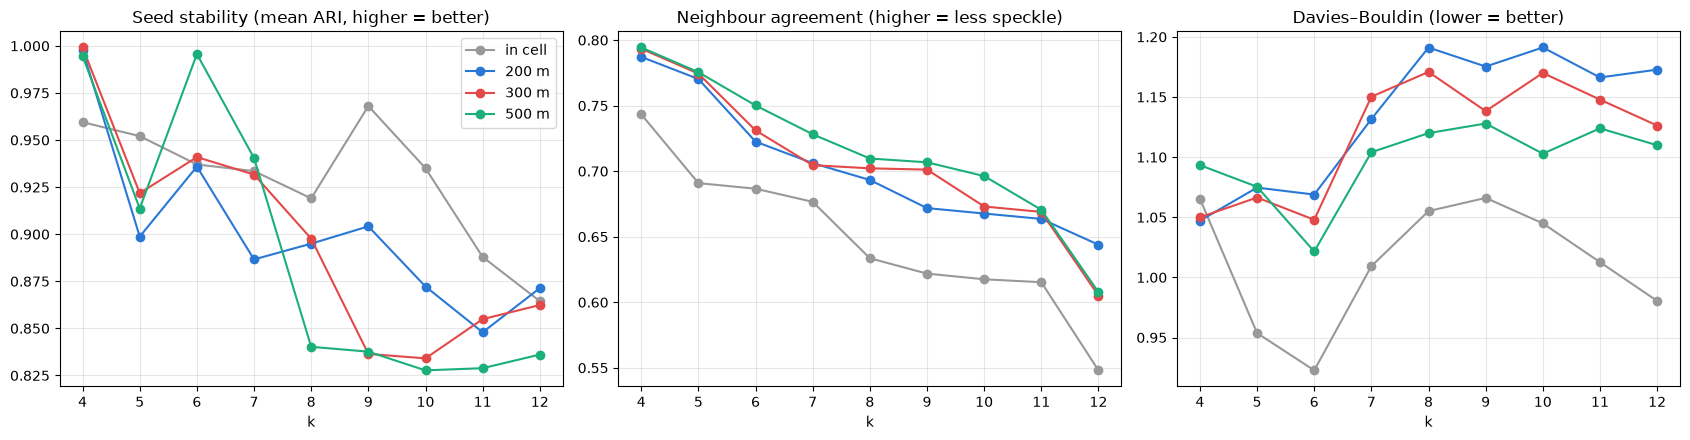

Most seed-stable k per radius:
radius
0      9
200    4
300    4
500    6


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for radius, color in zip(RADII, ["#999999", "#2a78d6", "#e34948", "#1baf7a"]):
    s = scores.loc[radius]
    name = "in cell" if radius == 0 else f"{radius} m"
    axes[0].plot(s.index, s["seed_ari_mean"], "o-", color=color, label=name)
    axes[1].plot(s.index, s["neighbour_agreement"], "o-", color=color, label=name)
    axes[2].plot(s.index, s["davies_bouldin"], "o-", color=color, label=name)
axes[0].set_title("Seed stability (mean ARI, higher = better)")
axes[1].set_title("Neighbour agreement (higher = less speckle)")
axes[2].set_title("Davies–Bouldin (lower = better)")
for ax in axes:
    ax.set_xlabel("k")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
fig.savefig(FIGURES / "08_scores_by_radius.png", dpi=150, bbox_inches="tight")
plt.show()

print("Most seed-stable k per radius:")
print(scores["seed_ari_mean"].groupby("radius").idxmax().map(lambda t: t[1]).to_string())

## 5. How similar are the radii? (ARI between clusterings)
For k = 5 and k = 6: ARI between every pair of radii. Values close to 1 mean the radius choice hardly matters.

In [6]:
names = {r: ("in cell" if r == 0 else f"{r} m") for r in RADII}
for k in (5, 6):
    m = pd.DataFrame(
        [[adjusted_rand_score(labels[a, k], labels[b, k]) for b in RADII] for a in RADII],
        index=[names[r] for r in RADII], columns=[names[r] for r in RADII],
    ).round(3)
    print(f"k = {k}")
    display(m)

k = 5


,in cell,200 m,300 m,500 m
in cell,1.000,0.868,0.858,0.848
200 m,0.868,1.000,0.960,0.925
300 m,0.858,0.960,1.000,0.945
500 m,0.848,0.925,0.945,1.000


k = 6


,in cell,200 m,300 m,500 m
in cell,1.000,0.868,0.866,0.877
200 m,0.868,1.000,0.950,0.883
300 m,0.866,0.950,1.000,0.905
500 m,0.877,0.883,0.905,1.000


## 6. Does the residential split survive? (k = 6)
For each radius, the medians of the original variables per cluster. We look for two residential clusters that differ in density
(population, height, POI nearby) – the split we found at 300 m.

In [7]:
profiles = []
for radius in RADII:
    X = build_Z(radius)[0]
    raw = data.loc[X.index, ["pop", "bld_height", "imp_share", "can_cover"]].assign(
        poi=np.expm1(X["poi"]), str_intersections=np.expm1(X["str_intersections"]))
    g = raw.groupby(labels[radius, 6])
    p = g.median().round(2)
    p.insert(0, "cells", g.size())
    p.insert(1, "residents", g["pop"].sum().astype(int))
    p.insert(0, "radius", names[radius])
    profiles.append(p)
profiles = pd.concat(profiles).rename_axis("cluster").reset_index().set_index(["radius", "cluster"])
profiles

cells  residents   pop  bld_height  imp_share  can_cover  \
radius  cluster                                                             
in cell 0        11412        433   0.0        0.00       0.00       0.96   
        1         9145       1326   0.0        0.00       0.00       0.08   
        2         2611     131030  24.0        7.91       0.32       0.09   
        3         2029      88501  29.0        8.08       0.46       0.08   
        4         1044      78802  37.0       12.18       0.67       0.09   
        5         1224        334   0.0        9.60       0.73       0.03   
200 m   0        11304        131   0.0        0.00       0.00       0.96   
        1         8287        125   0.0        0.00       0.00       0.08   
        2         3159      29363   6.0        7.42       0.16       0.11   
        3         2770     204649  51.0        8.51       0.52       0.08   
        4          623      65605  67.0       17.27       0.73       0.11   
        5         1322        553   0.0        9.61       0.75       0.04   
300 m   0        11331        135   0.0        0.00       0.00       0.96   
        1         8395        125   0.0        0.00       0.00       0.08   
        2         3103      33918   7.0        7.45       0.17       0.10   
        3         2670     204338  53.0        8.59       0.53       0.08   
        4         1376        417   0.0        9.44       0.74       0.04   
        5          590      61493  63.0       17.76       0.73       0.10   
500 m   0        11449        244   0.0        0.00       0.00       0.96   
        1         8886        405   0.0        0.00       0.00       0.08   
        2         2917      57931  13.0        7.58       0.23       0.08   
        3         2241     210109  64.0        9.35       0.56       0.09   
        4         1617        560   0.0        9.25       0.70       0.04   
        5          355      31177  45.0       19.46       0.76       0.11   

                  poi  str_intersections  
radius  cluster                           
in cell 0        0.00               0.00  
        1        0.00               0.00  
        2        0.00               0.00  
        3        0.00               1.00  
        4        2.00               1.00  
        5        0.00               0.00  
200 m   0        0.00               0.00  
        1        0.00               0.00  
        2        0.00               0.23  
        3        0.23               0.62  
        4        1.62               0.92  
        5        0.23               0.23  
300 m   0        0.00               0.00  
        1        0.00               0.03  
        2        0.03               0.21  
        3        0.28               0.59  
        4        0.28               0.38  
        5        1.52               0.90  
500 m   0        0.00               0.00  
        1        0.01               0.07  
        2        0.05               0.22  
        3        0.40               0.59  
        4        0.30               0.44  
        5        1.93               1.01

**Cross-tables against 300 m** (k = 6): where do the 300 m clusters end up at 200 m and 500 m? Rows = 300 m clusters, values = share of the row.

In [8]:
for radius in (200, 500):
    print(f"300 m (rows) vs {radius} m (columns), k = 6")
    display(pd.crosstab(labels[300, 6].rename("300 m"), labels[radius, 6].rename(f"{radius} m"), normalize="index").round(2))

300 m (rows) vs 200 m (columns), k = 6


200 m,0,1,2,3,4,5
300 m,,,,,,
0,0.99,0.00,0.00,0.00,0.00,0.00
1,0.00,0.97,0.03,0.00,0.00,0.00
2,0.00,0.03,0.90,0.07,0.00,0.01
3,0.00,0.00,0.03,0.94,0.03,0.00
4,0.00,0.01,0.05,0.01,0.02,0.91
5,0.00,0.00,0.00,0.08,0.87,0.05


300 m (rows) vs 500 m (columns), k = 6


500 m,0,1,2,3,4,5
300 m,,,,,,
0,1.00,0.00,0.00,0.00,0.00,0.00
1,0.01,0.98,0.00,0.00,0.00,0.00
2,0.01,0.18,0.74,0.00,0.05,0.00
3,0.00,0.00,0.22,0.76,0.01,0.01
4,0.00,0.02,0.01,0.00,0.95,0.02
5,0.00,0.00,0.00,0.34,0.13,0.53


## 7. Maps (k = 6)

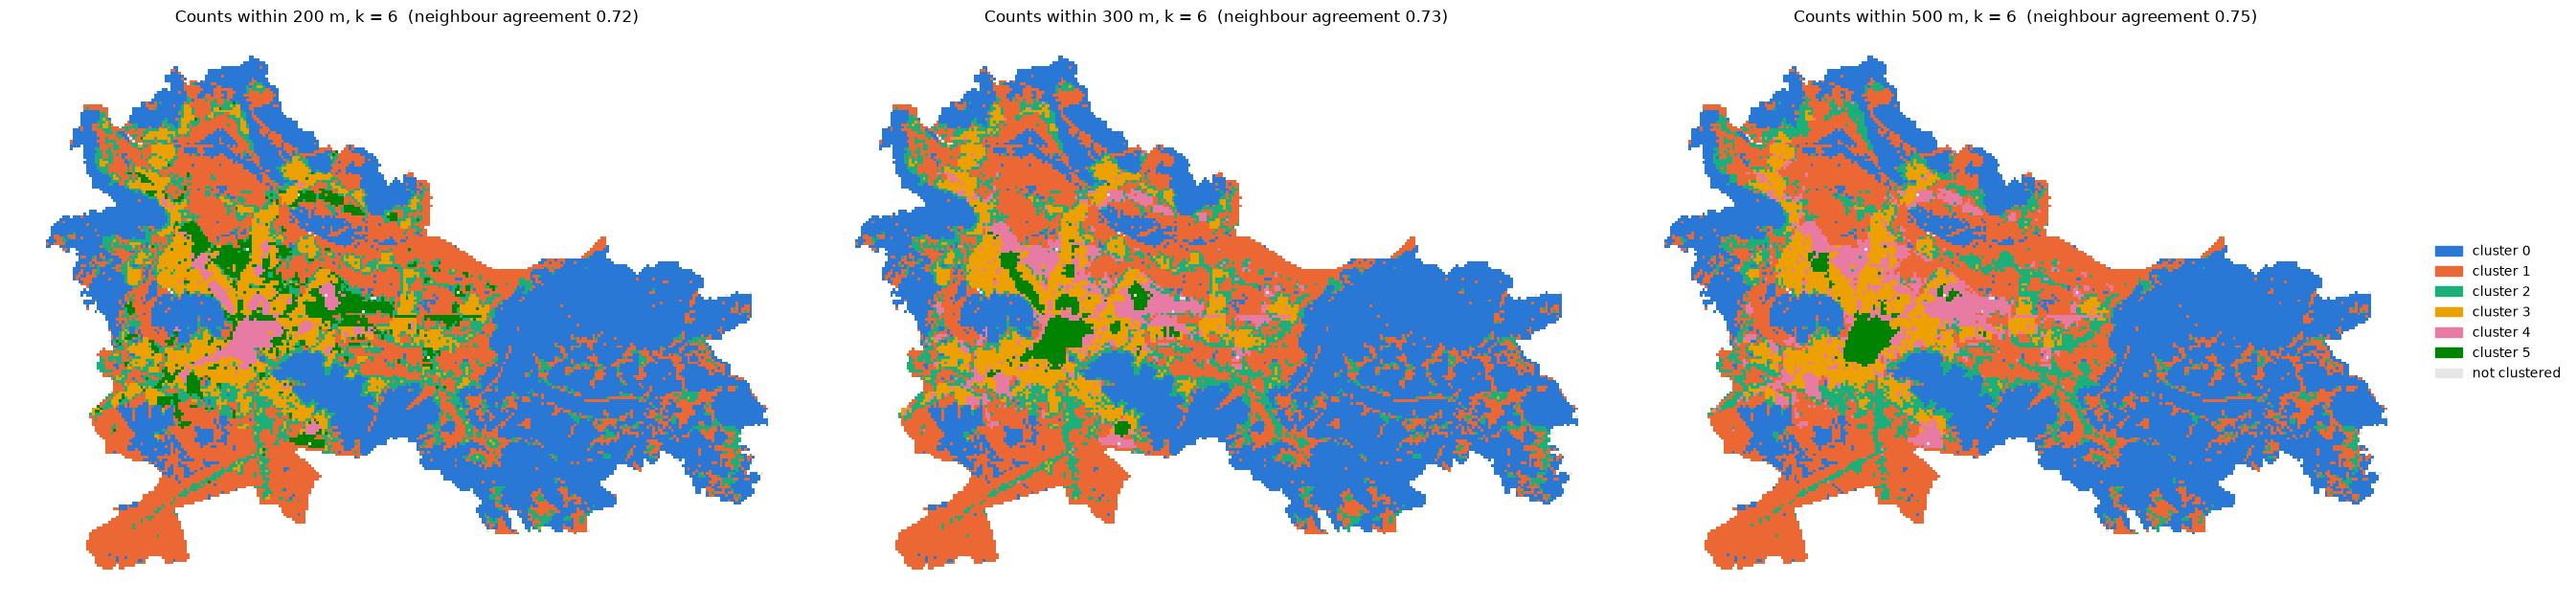

In [9]:
K = 6
cmap = ListedColormap(CLUSTER_COLORS[:K])
fig, axes = plt.subplots(1, 3, figsize=(27, 9))
for ax, radius in zip(axes, [200, 300, 500]):
    g_ = cells[["cell_id", "geometry"]].merge(labels[radius, K].rename("cluster").reset_index(), on="cell_id", how="left")
    g_[g_["cluster"].isna()].plot(ax=ax, color="#e6e6e6", linewidth=0)
    g_.dropna(subset=["cluster"]).plot(ax=ax, column="cluster", cmap=cmap, vmin=-0.5, vmax=K - 0.5, linewidth=0)
    ax.set_title(f"Counts within {radius} m, k = {K}  (neighbour agreement {scores.loc[(radius, K), 'neighbour_agreement']:.2f})")
    ax.set_axis_off()
handles = [Patch(color=CLUSTER_COLORS[c], label=f"cluster {c}") for c in range(K)] + [Patch(color="#e6e6e6", label="not clustered")]
axes[2].legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout()
fig.savefig(FIGURES / "08_maps_by_radius.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Save

In [10]:
scores.reset_index().to_csv(PROCESSED / "radius_sensitivity.csv", index=False)
print("Saved radius_sensitivity.csv")

Saved radius_sensitivity.csv


## Summary (first run, 1 Nov 2026)

**Speckle:** any radius removes most of it (neighbour agreement at k = 6: in cell 0.63, 200 m 0.68, 300 m 0.71, 500 m 0.73). Beyond 300 m the gain is small, and at k = 5 there is none (0.75 for both).

**Agreement between radii:**
- k = 5: the radius hardly matters (ARI 0.88–0.93 between 200, 300 and 500 m).
- k = 6: 300 m and 500 m agree (ARI 0.91); 200 m differs (ARI 0.81 vs 300 m).

**Meaning at k = 6:**
- 300 m and 500 m both give the split **low-density residential** (20–23 residents/ha) vs **dense urban residential** (65–72 residents/ha). The centre cluster gets smaller as the radius grows (458 → 270 cells): a larger window smooths secondary centres away.
- At 200 m the split is different: a small sparse fringe cluster (7 residents/ha) vs one big residential cluster with almost all residents, and a larger centre (617 cells). 200 m is too small a neighbourhood to separate the two residential types.
- Note: at 200 m the centre is cluster 4 and non-residential is cluster 5 (clusters are numbered by mean imperviousness), so the colours swap on the map.

**Choice of k:** k = 5 is the most seed-stable for 200 m and 300 m (ARI 0.999 / 0.997) but not for 500 m (0.89; k = 8 best there).

**Proposed:** keep **300 m**. It agrees with 500 m, gives a very stable k = 5, and keeps the centre compact without smoothing it away. Still open: k = 5 (stable) vs k = 6 (residential split, seed ARI 0.86).

---
### Re-run on all of MOL (1 Nov 2026)
27,465 cells instead of 16,351. Numbers above are from the first run.
- Neighbour agreement at k = 6: in cell 0.69, 200 m 0.72, 300 m 0.73, 500 m 0.75 – the same pattern as before.
- The radii agree more than before: ARI vs 300 m at k = 6 is 0.95 (200 m) and 0.91 (500 m); at k = 5 0.96 and 0.95.
- At k = 6, **all three radii now give the same structure**: sparse residential/villages (6–13 residents/ha) vs urban residential (51–64/ha), a centre that shrinks with the radius (623 → 590 → 355 cells), and non-residential.
- Most seed-stable k: 4 for 200 m and 300 m (ARI 0.999), 6 for 500 m (0.996). k = 6 at 300 m: 0.94.
- 300 m is still a reasonable choice; the k decision is now k = 4 (very stable, one residential cluster) vs k = 6.